# 6. Inferencia ideológica sobre el corpus completo
## Modelo: LoRA QKV r8 (Qwen3-4B · AutoModelForSequenceClassification)

In [1]:
# Verificar GPU disponible
import subprocess
result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else 'No GPU detectada — activa Runtime > Change runtime type > G4')

Mon May 25 19:21:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   30C    P0             48W /  600W |       0MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
!pip install -q -U transformers peft accelerate bitsandbytes datasets torchao pyarrow

In [3]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive montado correctamente')

Mounted at /content/drive
Drive montado correctamente


In [ ]:
import numpy as np
from pathlib import Path
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from peft import PeftModel
import time
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

## 1. Configuración

In [4]:
# Rutas
DRIVE_ROOT   = Path('/content/drive/MyDrive/TFM')
MODEL_DIR    = DRIVE_ROOT / 'qwen3_4b_lora_r8_qkv'
CORPUS_PATH  = DRIVE_ROOT / 'splits' / 'corpus_limpio_filtrado.parquet'
SPLITS_DIR   = DRIVE_ROOT / 'splits'
OUTPUT_PATH  = DRIVE_ROOT / 'inferencia_ideologica.csv'
FINAL_PATH   = DRIVE_ROOT / 'corpus_clasificado_final.csv'
MODEL_PATH   = MODEL_DIR / 'best_model' if (MODEL_DIR / 'best_model').exists() else MODEL_DIR

# Modelo base
BASE_MODEL   = 'Qwen/Qwen3-4B'

# Inferencia
BATCH_SIZE   = 16
SAVE_EVERY   = 5000
MAX_LENGTH   = 1024

LABEL2ID  = {'IZQUIERDA': 0, 'CENTRO': 1, 'DERECHA': 2}
ID2LABEL  = {0: 'IZQUIERDA', 1: 'CENTRO', 2: 'DERECHA'}
CLASES    = ['IZQUIERDA', 'CENTRO', 'DERECHA']

# Verificar rutas
for p, name in [(MODEL_PATH, 'Adaptador LoRA'), (CORPUS_PATH, 'Corpus')]:
    status = 'OK' if p.exists() else 'NO ENCONTRADO'
    print(f'{status}  {name}: {p}')

OK  Adaptador LoRA: /content/drive/MyDrive/TFM/qwen3_4b_lora_r8_qkv/best_model
OK  Corpus: /content/drive/MyDrive/TFM/splits/corpus_limpio_filtrado.parquet


## 2. Carga del modelo fine-tuneado

In [5]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Dispositivo: {DEVICE}')
if DEVICE == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

print('\nCargando tokenizer...')
tokenizer = AutoTokenizer.from_pretrained(str(MODEL_PATH), trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token    = tokenizer.eos_token
    tokenizer.pad_token_id = tokenizer.eos_token_id

print('Cargando modelo base Qwen3-4B (float16, clasificación)...')
base_model = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    torch_dtype=torch.float16,
    device_map='auto',
    trust_remote_code=True,
)

print('Cargando adaptador LoRA QKV r8...')
model = PeftModel.from_pretrained(base_model, str(MODEL_PATH))
model.config.pad_token_id = tokenizer.pad_token_id
model.eval()

if DEVICE == 'cuda':
    print(f'VRAM usada: {torch.cuda.memory_allocated() / 1e9:.1f} GB')
print('Modelo listo')

Dispositivo: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
VRAM: 102.0 GB

Cargando tokenizer...
Cargando modelo base Qwen3-4B (float16, clasificación)...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Cargando adaptador LoRA QKV r8...
VRAM usada: 8.1 GB
Modelo listo


## 3. Carga del corpus

In [6]:
df_corpus = pd.read_parquet(str(CORPUS_PATH))
print(f'Corpus total: {len(df_corpus):,} artículos')

# Reconstruir texto donde sea nulo (titular + abstract + noticia)
mask = df_corpus['texto'].isnull()
if mask.any():
    df_corpus.loc[mask, 'texto'] = (
        df_corpus.loc[mask, 'titular'].fillna('') + '. ' +
        df_corpus.loc[mask, 'abstract'].fillna('') + '. ' +
        df_corpus.loc[mask, 'noticia'].fillna('')
    )
    print(f'Texto reconstruido para {mask.sum():,} artículos')

# Excluir artículos con ground truth (train + val + test)
gt_frames = []
for split in ('df_train.parquet', 'df_val.parquet', 'df_test.parquet'):
    p = SPLITS_DIR / split
    if p.exists():
        df_s = pd.read_parquet(str(p))[['id', 'final_label']]
        df_s['split'] = split.replace('df_', '').replace('.parquet', '')
        gt_frames.append(df_s)

df_gt = pd.concat(gt_frames, ignore_index=True) if gt_frames else pd.DataFrame(columns=['id', 'final_label', 'split'])
gt_ids = set(df_gt['id'])
print(f'Artículos con ground truth: {len(gt_ids):,}  (train/val/test)')

df_sin_etiquetar = df_corpus[~df_corpus['id'].isin(gt_ids)].reset_index(drop=True)
print(f'Artículos a inferir:        {len(df_sin_etiquetar):,}')

# Retomar desde checkpoint si ya existe
if OUTPUT_PATH.exists():
    df_done      = pd.read_csv(str(OUTPUT_PATH))
    done_ids     = set(df_done['id'])
    df_pendiente = df_sin_etiquetar[~df_sin_etiquetar['id'].isin(done_ids)].reset_index(drop=True)
    print(f'\nCheckpoint encontrado: {len(done_ids):,} ya procesados')
    print(f'Pendientes: {len(df_pendiente):,} artículos')
else:
    df_pendiente = df_sin_etiquetar
    print(f'\nSin checkpoint previo — procesando {len(df_pendiente):,} artículos')

Corpus total: 241,240 artículos
Texto reconstruido para 176,304 artículos
Artículos con ground truth: 2,378  (train/val/test)
Artículos a inferir:        238,862

Checkpoint encontrado: 238,862 ya procesados
Pendientes: 0 artículos


## 4. Función de inferencia

In [ ]:
def inferir_batch(textos: list[str]) -> tuple[list[str], list[float], np.ndarray]:
    """
    Clasifica una lista de textos usando la cabeza de clasificación del modelo.
    Devuelve (predicciones, confianzas, probs[N,3]).
    Sin prompts: el modelo recibe el texto directamente.
    """
    enc = tokenizer(
        textos,
        truncation=True,
        max_length=MAX_LENGTH,
        padding=True,
        return_tensors='pt',
    )
    enc = {k: v.to(DEVICE) for k, v in enc.items()}

    with torch.no_grad():
        logits = model(**enc).logits              # (batch, 3)
        probs  = torch.softmax(logits, dim=-1).cpu().float().numpy()

    predicciones = [ID2LABEL[int(np.argmax(p))] for p in probs]
    confianzas   = [float(np.max(p))             for p in probs]
    return predicciones, confianzas, probs


# Test rápido con 2 artículos
test_textos = df_pendiente['texto'].iloc[:2].tolist()
preds, confs, _ = inferir_batch(test_textos)
for t, p, c in zip(test_textos, preds, confs):
    print(f'  [{p} | conf={c:.3f}]  {t[:80]}...')
print('Función de inferencia OK')

## 5. Inferencia sobre el corpus completo (con checkpointing)

In [8]:
if OUTPUT_PATH.exists():
    try:
        df_done = pd.read_csv(str(OUTPUT_PATH))
        assert 'id' in df_done.columns, "CSV sin columna 'id'"
        done_ids = set(df_done['id'])
        df_pendiente = df_sin_etiquetar[~df_sin_etiquetar['id'].isin(done_ids)].reset_index(drop=True)
        print(f'Checkpoint encontrado: {len(done_ids):,} ya procesados')
        print(f'Pendientes: {len(df_pendiente):,} artículos')
    except Exception as e:
        print(f'Checkpoint corrupto ({e}), empezando desde cero')
        OUTPUT_PATH.unlink()  # borra el CSV dañado
        df_pendiente = df_sin_etiquetar
else:
    df_pendiente = df_sin_etiquetar
    print(f'Sin checkpoint previo, procesando {len(df_pendiente):,} artículos')

Checkpoint encontrado: 238,862 ya procesados
Pendientes: 0 artículos


In [9]:
buffer      = []
n_total     = len(df_pendiente)
n_done      = 0
first_write = not OUTPUT_PATH.exists()
t_start     = time.time()

def guardar_buffer(buf, path, first_write):
    pd.DataFrame(buf).to_csv(
        str(path), mode='w' if first_write else 'a',
        header=first_write, index=False,
    )
    return []

pbar = tqdm(total=n_total, desc='Inferencia', unit='art')

for i in range(0, n_total, BATCH_SIZE):
    batch = df_pendiente.iloc[i : i + BATCH_SIZE]
    textos = batch['texto'].tolist()

    try:
        preds, confs, probs = inferir_batch(textos)
    except RuntimeError:
        torch.cuda.empty_cache()
        preds, confs, probs = [], [], []
        for texto in textos:
            p, c, pr = inferir_batch([texto])
            preds += p; confs += c; probs.append(pr[0])
        probs = np.array(probs)

    for j, row in enumerate(batch.itertuples(index=False)):
        buffer.append({
            'id':          row.id,
            'medio':       row.medio,
            'fecha':       row.fecha,
            'pred_label':  preds[j],
            'confianza':   round(confs[j], 4),
            'p_izquierda': round(float(probs[j][0]), 4),
            'p_centro':    round(float(probs[j][1]), 4),
            'p_derecha':   round(float(probs[j][2]), 4),
        })

    n_done += len(batch)
    pbar.update(len(batch))

    if n_done % SAVE_EVERY < BATCH_SIZE:
        buffer      = guardar_buffer(buffer, OUTPUT_PATH, first_write)
        first_write = False
        elapsed = time.time() - t_start
        rate    = n_done / elapsed
        eta     = (n_total - n_done) / rate if rate > 0 else 0
        tqdm.write(f'  Checkpoint: {n_done:,}/{n_total:,} | {rate:.1f} art/s | ETA {eta/60:.0f} min')

pbar.close()

if buffer:
    guardar_buffer(buffer, OUTPUT_PATH, first_write)

elapsed = time.time() - t_start
print(f'\nInferencia completa: {n_done:,} artículos en {elapsed/60:.1f} min ({n_done/elapsed:.1f} art/s)')
print(f'Resultado guardado en: {OUTPUT_PATH}')

Inferencia: 0art [00:00, ?art/s]


Inferencia completa: 0 artículos en 0.0 min (0.0 art/s)
Resultado guardado en: /content/drive/MyDrive/TFM/inferencia_ideologica.csv


## 6. Validación y resumen de resultados

In [10]:
df_result = pd.read_csv(str(OUTPUT_PATH))
print(f'Total filas guardadas: {len(df_result):,}')
print(f'IDs únicos:            {df_result["id"].nunique():,}')
print(f'DESCONOCIDO:           {(df_result["pred_label"]=="DESCONOCIDO").sum():,}')

print('\n— Distribución global —')
print(df_result['pred_label'].value_counts())

print('\n— Distribución por medio —')
print(df_result.groupby('medio')['pred_label'].value_counts(normalize=True).mul(100).round(1))

Total filas guardadas: 238,862
IDs únicos:            238,862
DESCONOCIDO:           0

— Distribución global —
pred_label
CENTRO       99873
IZQUIERDA    82609
DERECHA      56380
Name: count, dtype: int64

— Distribución por medio —
medio            pred_label
El Confidencial  CENTRO        62.6
                 DERECHA       19.3
                 IZQUIERDA     18.1
El Mundo         DERECHA       42.7
                 CENTRO        35.4
                 IZQUIERDA     21.9
El País          IZQUIERDA     47.2
                 CENTRO        44.1
                 DERECHA        8.6
OKDiario         DERECHA       53.5
                 CENTRO        42.5
                 IZQUIERDA      4.0
Público          IZQUIERDA     64.4
                 CENTRO        26.2
                 DERECHA        9.3
elDiario.es      IZQUIERDA     57.8
                 CENTRO        31.3
                 DERECHA       10.9
Name: proportion, dtype: float64


### Análisis de la distribución de predicciones

**Distribución global:**
- **CENTRO** (41.8%) es la clase dominante: coherente con la naturaleza factual de gran parte del corpus (noticias de economía, sucesos, deportes), donde el lenguaje es más neutro.
- **IZQUIERDA** (34.6%) supera a **DERECHA** (23.6%), lo que refleja la mayor presencia de medios progresistas en el corpus (elDiario.es, Público, El País).
- **0 predicciones DESCONOCIDO**: el modelo clasifica con confianza todos los artículos, sin casos de ambigüedad extrema.

**Por medio — coherencia editorial:**

| Medio | Clase predominante | % |
|---|---|---|
| Público | IZQUIERDA | 64.4% |
| elDiario.es | IZQUIERDA | 57.8% |
| El País | IZQUIERDA | 47.2% |
| El Confidencial | CENTRO | 62.6% |
| El Mundo | DERECHA | 42.7% |
| OKDiario | DERECHA | 53.5% |

Las predicciones son altamente coherentes con el posicionamiento editorial conocido de cada cabecera. Los medios marcadamente ideológicos (Público, OKDiario) presentan los porcentajes más altos en su clase esperada, mientras que El Confidencial, reconocido como el medio más centrista del corpus, obtiene la mayor concentración en CENTRO.

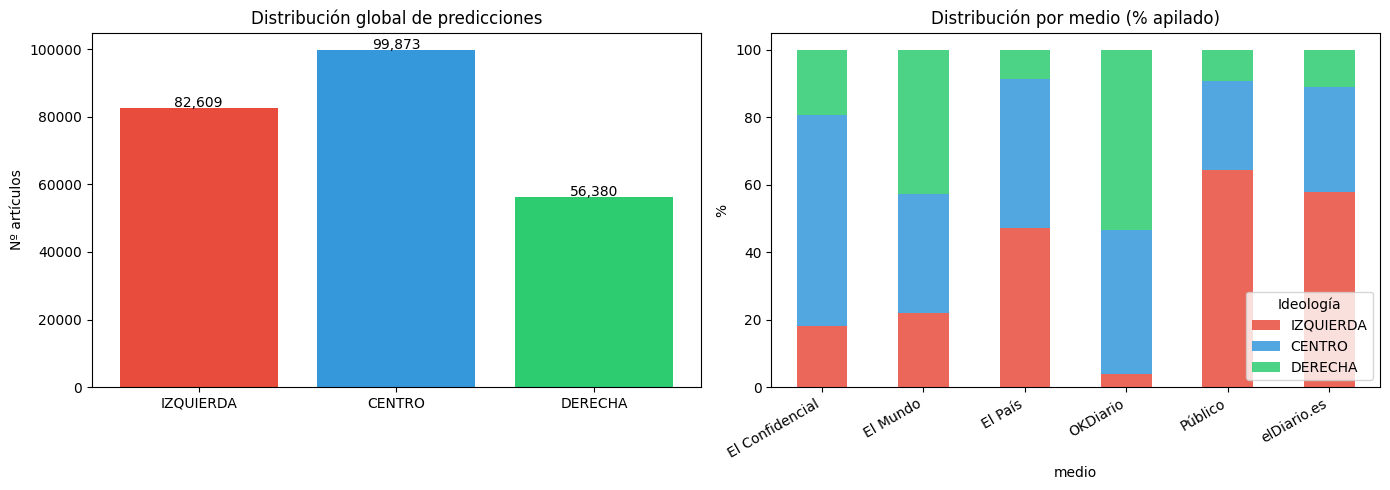

Gráfica guardada en Drive


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución global
counts = df_result['pred_label'].value_counts().reindex(CLASES, fill_value=0)
axes[0].bar(CLASES, counts.values, color=['#e74c3c', '#3498db', '#2ecc71'])
axes[0].set_title('Distribución global de predicciones')
axes[0].set_ylabel('Nº artículos')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 200, f'{v:,}', ha='center', fontsize=10)

# Distribución por medio (% apilado)
pivot = (df_result.groupby(['medio', 'pred_label'])
         .size().unstack(fill_value=0)
         .reindex(columns=CLASES, fill_value=0))
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100
pivot_pct.plot(
    kind='bar', stacked=True, ax=axes[1],
    color=['#e74c3c', '#3498db', '#2ecc71'], alpha=0.85
)
axes[1].set_title('Distribución por medio (% apilado)')
axes[1].set_ylabel('%')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')
axes[1].legend(title='Ideología')

plt.tight_layout()
plt.savefig(str(DRIVE_ROOT / 'inferencia_distribucion.png'), dpi=150)
plt.show()
print('Gráfica guardada en Drive')

**Distribución global de predicciones:**
El sesgo hacia CENTRO confirma que el modelo no "fuerza" etiquetas ideológicas extremas: una parte importante del contenido periodístico es descriptivo y factual. La distancia entre IZQUIERDA y DERECHA (~26K artículos) es consecuencia directa del desequilibrio de medios en el corpus, no necesariamente de un sesgo del modelo.

**Distribución por medio (% apilado):**
Visualmente se aprecia la polarización del panorama mediático español:
- La mitad izquierda de la gráfica (Público, elDiario.es, El País) está dominada por el rojo (IZQUIERDA).
- El Confidencial muestra el perfil más equilibrado, con CENTRO dominante y márgenes similares en IZQUIERDA y DERECHA.
- OKDiario y El Mundo forman el polo derecho, aunque con una fracción notable de CENTRO que refleja la cobertura de noticias no opinativas.

En conjunto, el modelo discrimina correctamente entre estilos editoriales muy distintos, lo que valida su capacidad de generalización al corpus no etiquetado.

## 7. Combinación final: ground truth + inferencia

Los artículos con etiqueta original (train/val/test) conservan su label gold.
Los restantes (~238 K) usan la predicción del modelo.
Se añade `label_source` para distinguir la procedencia.

In [12]:
# Bloque de inferencia (artículos sin etiquetar)
df_inferencia = pd.read_csv(str(OUTPUT_PATH))
df_inferencia['label_source'] = 'inference'
df_inferencia = df_inferencia.rename(columns={'pred_label': 'label'})

# Bloque ground truth (train + val + test)
cols_corpus = ['id', 'medio', 'fecha']
df_gt_enriquecido = (
    df_corpus[cols_corpus]
    .merge(df_gt[['id', 'final_label', 'split']], on='id', how='inner')
    .rename(columns={'final_label': 'label', 'split': 'label_source'})
)
# Añadir columnas de probabilidad como NaN (no disponibles para ground truth)
for col in ['confianza', 'p_izquierda', 'p_centro', 'p_derecha']:
    df_gt_enriquecido[col] = float('nan')

# Concatenar y verificar
df_final = pd.concat([df_inferencia, df_gt_enriquecido], ignore_index=True)
df_final = df_final.sort_values('id').reset_index(drop=True)

print(f'Total artículos clasificados: {len(df_final):,}')
print(f'  — Inferencia (modelo):  {(df_final["label_source"]=="inference").sum():,}')
print(f'  — Ground truth (train): {(df_final["label_source"]=="train").sum():,}')
print(f'  — Ground truth (val):   {(df_final["label_source"]=="val").sum():,}')
print(f'  — Ground truth (test):  {(df_final["label_source"]=="test").sum():,}')
print(f'\nDistribución global:')
print(df_final['label'].value_counts().to_string())
print(f'\nIDs sin clasificar: {len(df_corpus) - len(df_final):,}')

df_final.to_csv(str(FINAL_PATH), index=False)
print(f'\nGuardado en: {FINAL_PATH}')

Total artículos clasificados: 241,240
  — Inferencia (modelo):  238,862
  — Ground truth (train): 1,902
  — Ground truth (val):   238
  — Ground truth (test):  238

Distribución global:
label
CENTRO       100831
IZQUIERDA     83449
DERECHA       56960

IDs sin clasificar: 0

Guardado en: /content/drive/MyDrive/TFM/corpus_clasificado_final.csv
